# TAREA 3 - REDUCCIÓN DE DIMENSIONALIDAD CON PCA EN R (CAR EVALUATION)
# Asignatura: Aprendizaje Automático | UAO | Prof. Juan Camilo Giraldo

In [3]:
install.packages(c("FactoMineR", "factoextra", "ggplot2", "dplyr", "scatterplot3d", "plotly"))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘colorspace’, ‘fracdiff’, ‘lmtest’, ‘timeDate’, ‘urca’, ‘zoo’, ‘RcppArmadillo’, ‘Deriv’, ‘forecast’, ‘rbibutils’, ‘doBy’, ‘SparseM’, ‘MatrixModels’, ‘Rdpack’, ‘minqa’, ‘nloptr’, ‘reformulas’, ‘RcppEigen’, ‘corrplot’, ‘carData’, ‘abind’, ‘Formula’, ‘pbkrtest’, ‘quantreg’, ‘lme4’, ‘estimability’, ‘mvtnorm’, ‘numDeriv’, ‘showtextdb’, ‘viridis’, ‘ggsci’, ‘cowplot’, ‘ggsignif’, ‘gridExtra’, ‘polynom’, ‘rstatix’, ‘lazyeval’, ‘car’, ‘DT’, ‘ellipse’, ‘emmeans’, ‘flashClust’, ‘ggrepel’, ‘irlba’, ‘leaps’, ‘multcompView’, ‘showtext’, ‘sysfonts’, ‘dendextend’, ‘ggpubr’, ‘crosstalk’




Loading required package: ggplot2

Welcome to factoextra!

Want to learn more? See two factoextra-related books at https://www.datanovia.com/library/principal-component-methods


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




Dimensiones del dataset: 1728 filas x 7 columnas
Valores faltantes totales: 0 

  acc  good unacc vgood 
  384    69  1210    65 

Medias tras estandarizar:
  buying    maint    doors  persons lug_boot   safety 
       0        0        0        0        0        0 
Desviaciones estándar:
  buying    maint    doors  persons lug_boot   safety 
       1        1        1        1        1        1 

Matriz de correlación:
         buying maint doors persons lug_boot safety
buying        1     0     0       0        0      0
maint         0     1     0       0        0      0
doors         0     0     1       0        0      0
persons       0     0     0       1        0      0
lug_boot      0     0     0       0        1      0
safety        0     0     0       0        0      1
¿Correlación = identidad?: TRUE 

=== MÉTODO 1: SVD ===
 Componente Valor_Singular Autovalor Varianza_Explicada_pct
        PC1          41.56         1                  16.67
        PC2          41.56         1

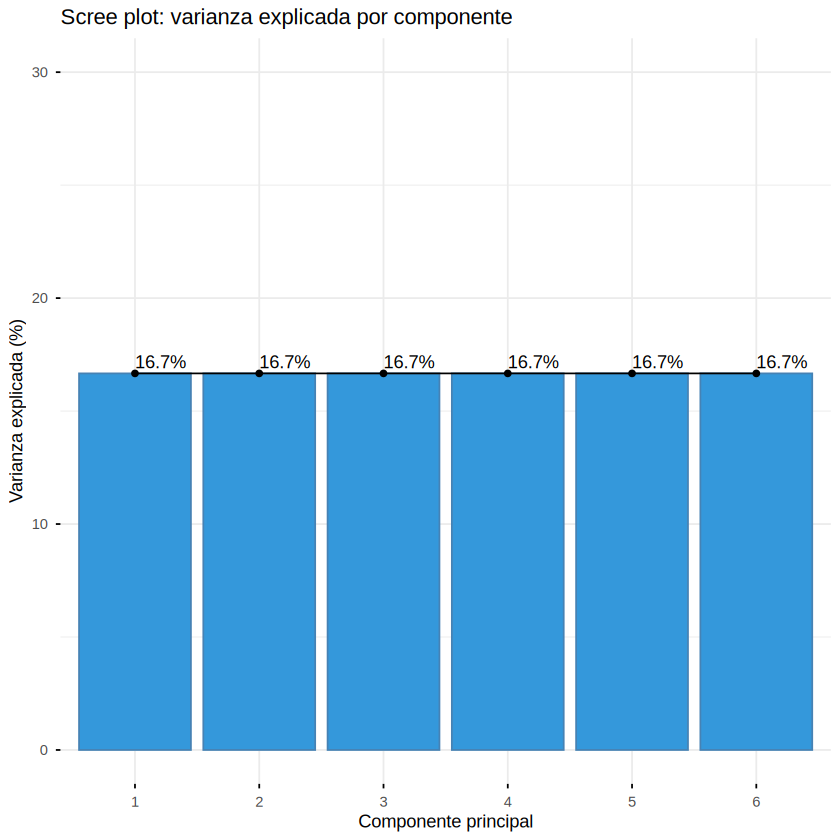

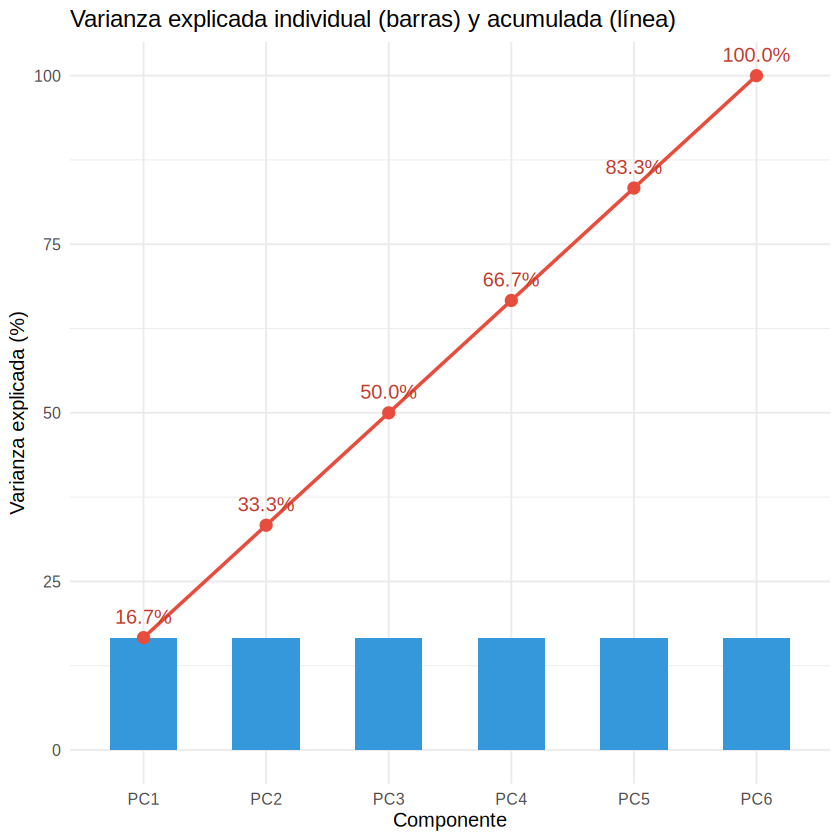

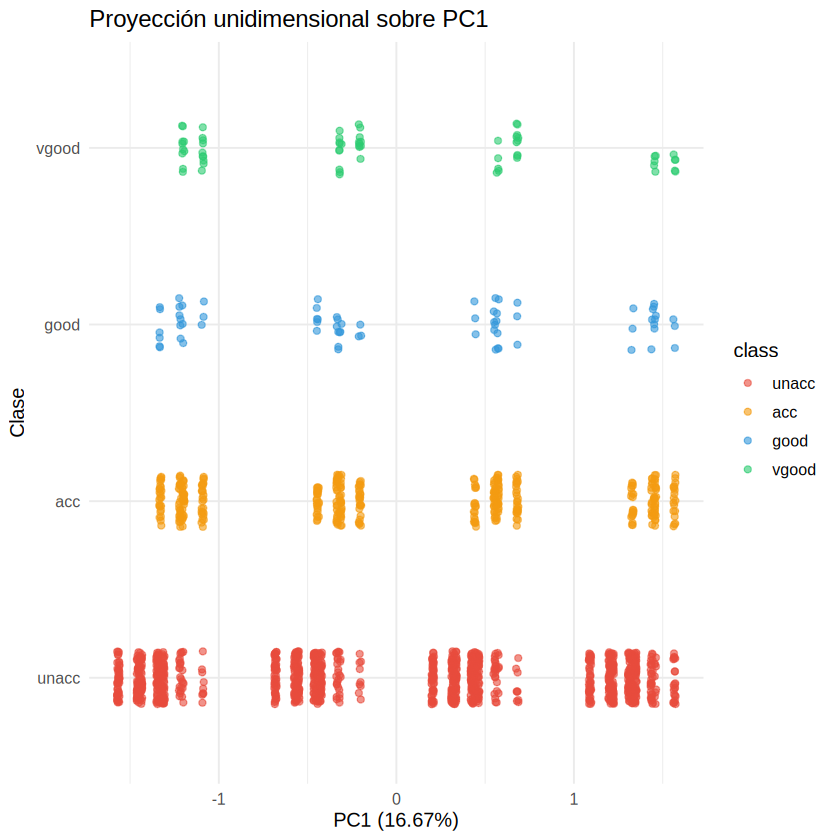

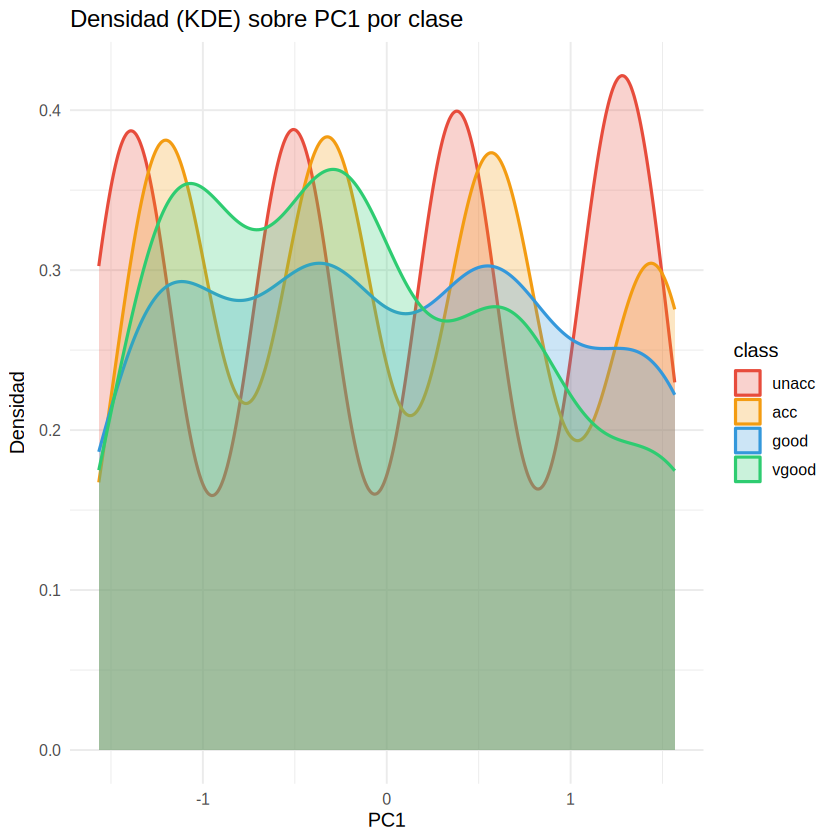

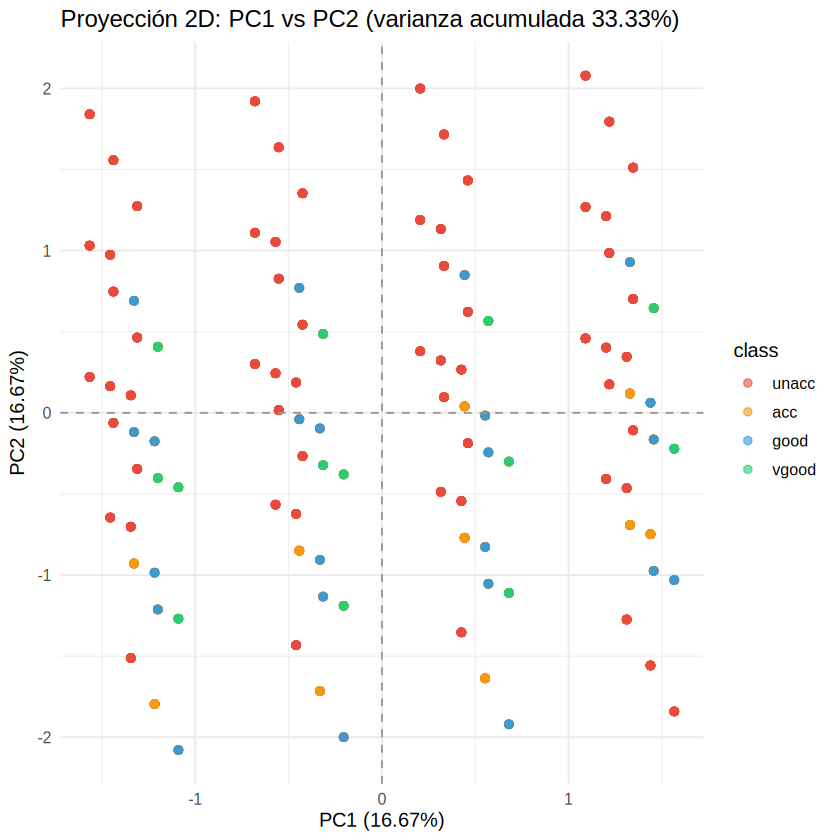

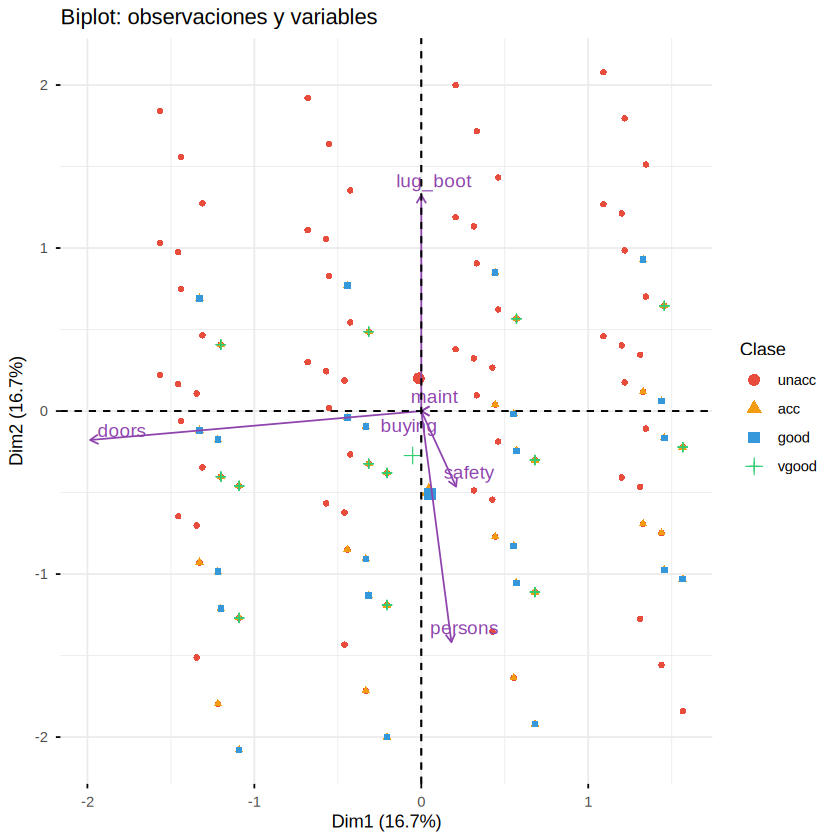

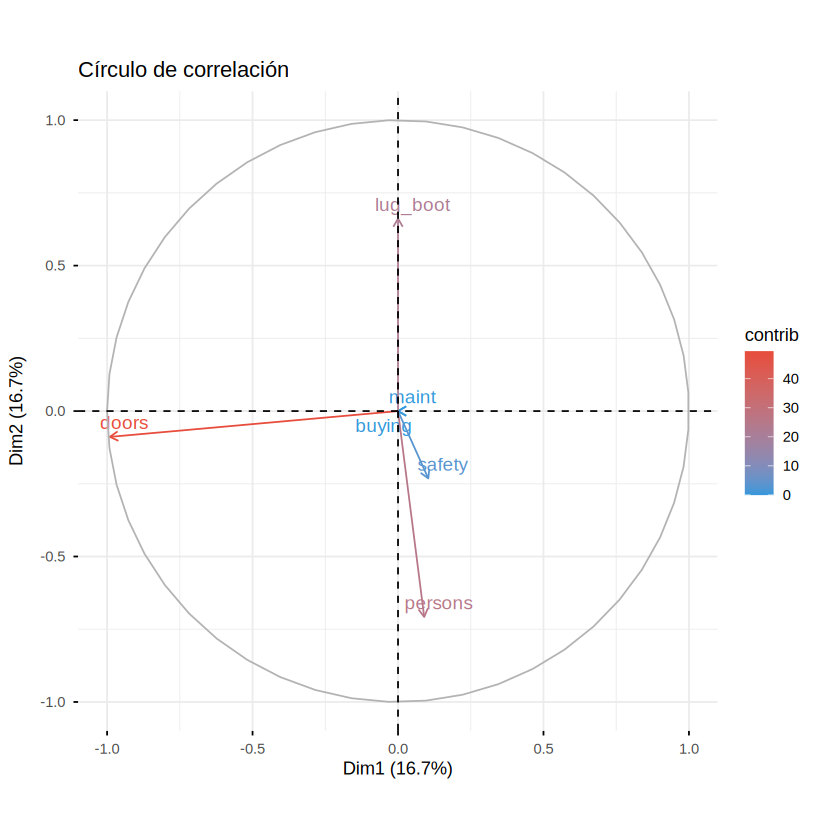


Attaching package: ‘plotly’


The following object is masked from ‘package:ggplot2’:

    last_plot


The following object is masked from ‘package:stats’:

    filter


The following object is masked from ‘package:graphics’:

    layout





=== RESUMEN: varianza explicada acumulada ===
 k Varianza_SVD_pct Varianza_prcomp_pct
 1            16.67               16.67
 2            33.33               33.33
 3            50.00               50.00


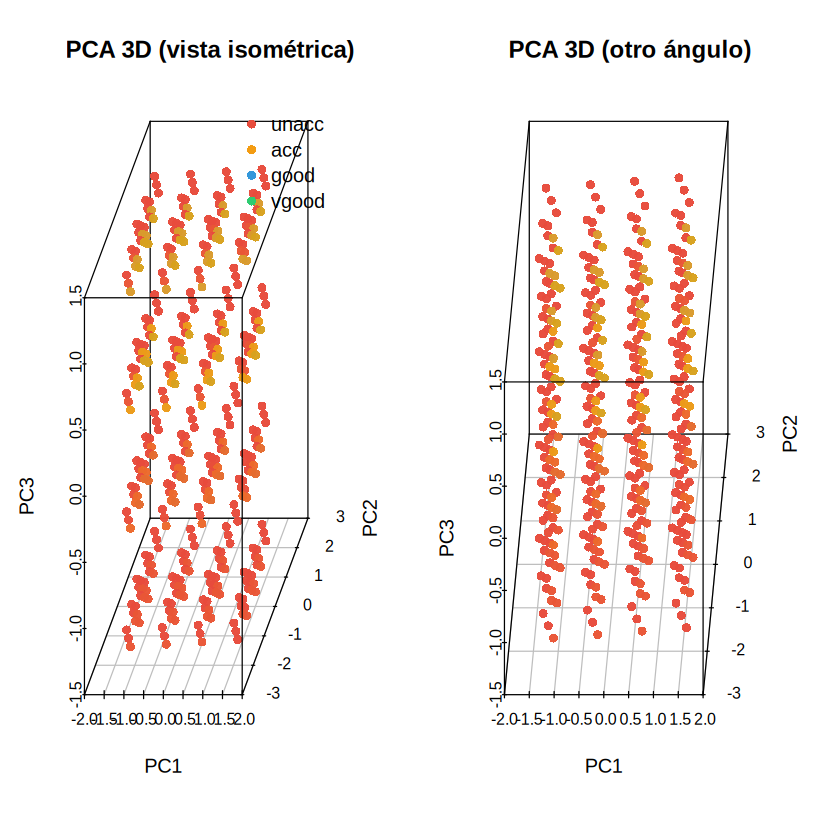

In [4]:

# install.packages(c("FactoMineR", "factoextra", "ggplot2", "dplyr", "scatterplot3d", "plotly"))

library(FactoMineR)
library(factoextra)
library(ggplot2)
library(dplyr)
library(scatterplot3d)

set.seed(25)

colores_clases <- c(unacc = "#e74c3c", acc = "#f39c12", good = "#3498db", vgood = "#2ecc71")

# CARGA DEL DATASET CAR EVALUATION

columnas <- c("buying", "maint", "doors", "persons", "lug_boot", "safety", "class")

ruta_local <- "car+evaluation/car.data"
url_remota <- "https://raw.githubusercontent.com/tdavidvergara/car_evaluation_pca/main/car%2Bevaluation/car.data"

if (file.exists(ruta_local)) {
  df_raw <- read.csv(ruta_local, header = FALSE, col.names = columnas, stringsAsFactors = FALSE)
} else {
  df_raw <- read.csv(url_remota, header = FALSE, col.names = columnas, stringsAsFactors = FALSE)
}

cat("Dimensiones del dataset:", nrow(df_raw), "filas x", ncol(df_raw), "columnas\n")
cat("Valores faltantes totales:", sum(is.na(df_raw)), "\n")
print(table(df_raw$class))

# PREPROCESAMIENTO Y CODIFICACIÓN ORDINAL JUSTIFICADA

# Las 6 variables predictoras tienen jerarquía física monótona (precio, puertas,
# pasajeros, maletero y seguridad). La codificación ordinal mantiene el espacio
# en p = 6 dimensiones continuas y evita la fragmentación artificial y
# colinealidad perfecta de One-Hot Encoding (21 dummies con rango 15).

df_pca <- df_raw %>%
  mutate(
    buying   = as.numeric(factor(buying,   levels = c("low", "med", "high", "vhigh"), ordered = TRUE)),
    maint    = as.numeric(factor(maint,    levels = c("low", "med", "high", "vhigh"), ordered = TRUE)),
    doors    = dplyr::recode(doors,   "2" = 2, "3" = 3, "4" = 4, "5more" = 5),
    persons  = dplyr::recode(persons, "2" = 2, "4" = 4, "more"  = 6),
    lug_boot = as.numeric(factor(lug_boot, levels = c("small", "med", "big"), ordered = TRUE)),
    safety   = as.numeric(factor(safety,   levels = c("low", "med", "high"), ordered = TRUE)),
    class    = factor(class, levels = c("unacc", "acc", "good", "vgood"))
  )

# Matriz numérica pura X (6 predictoras) y variable de clase
X <- as.matrix(df_pca[, 1:6])
y <- df_pca$class
n <- nrow(X); p <- ncol(X)


# El dataset cuenta con 1,728 instancias completas (sin NAs), distribuidas en
# unacc (1,210), acc (384), good (69) y vgood (65), listas para PCA y SVD.

#ESTANDARIZACIÓN (Z-score) Y MATRIZ DE CORRELACIÓN

# scale() usa desviación estándar muestral (n-1). Para PCA esto solo reescala
# los autovalores por una constante; la varianza explicada (%) no cambia.
X_std <- scale(X, center = TRUE, scale = TRUE)

cat("\nMedias tras estandarizar:\n");  print(round(colMeans(X_std), 6))
cat("Desviaciones estándar:\n");        print(round(apply(X_std, 2, sd), 6))

matriz_corr <- cor(X_std)
cat("\nMatriz de correlación:\n"); print(round(matriz_corr, 4))


# Las 1,728 instancias son el producto cartesiano completo (4x4x4x3x3x3), por lo
# que las variables son ortogonales: la matriz de correlación es la identidad.
# Consecuencia: los 6 autovalores son iguales y cada componente explica 16.67%.
cat("¿Correlación = identidad?:", isTRUE(all.equal(matriz_corr, diag(p), check.attributes = FALSE)), "\n")

#PCA CON SVD (MANUAL, svd() DE R BASE)

# X_std = U %*% diag(d) %*% t(V)
sv <- svd(X_std)
V_svd <- sv$v                              # columnas = direcciones principales (loadings)
autoval_svd <- sv$d^2 / (n - 1)            # autovalores lambda_i = s_i^2 / (n-1)
evr_svd     <- autoval_svd / sum(autoval_svd)
evr_svd_acum <- cumsum(evr_svd)

# Proyecciones para k = 1, 2 y 3 componentes
Z_svd_1 <- X_std %*% V_svd[, 1, drop = FALSE]
Z_svd_2 <- X_std %*% V_svd[, 1:2]
Z_svd_3 <- X_std %*% V_svd[, 1:3]

tabla_svd <- data.frame(
  Componente = paste0("PC", 1:p),
  Valor_Singular = sv$d,
  Autovalor = autoval_svd,
  Varianza_Explicada_pct = evr_svd * 100,
  Varianza_Acumulada_pct = evr_svd_acum * 100
)
cat("\n=== MÉTODO 1: SVD ===\n")
print(tabla_svd, digits = 4, row.names = FALSE)
cat("Dimensiones proyecciones: k=1", dim(Z_svd_1), "| k=2", dim(Z_svd_2), "| k=3", dim(Z_svd_3), "\n")


# 6. MÉTODO 2: PCA CON LIBRERÍAS DE R (prcomp y FactoMineR)

# prcomp() es el equivalente directo de sklearn.decomposition.PCA (usa SVD).
# Ya estandarizamos X_std, así que center = FALSE, scale. = FALSE.
pca_full <- prcomp(X_std, center = FALSE, scale. = FALSE)
Z_pr_full <- pca_full$x
evr_pr <- pca_full$sdev^2 / sum(pca_full$sdev^2)
evr_pr_acum <- cumsum(evr_pr)

# Casos k = 1, 2, 3 (se obtienen truncando las primeras k columnas de scores)
Z_pr_1 <- Z_pr_full[, 1, drop = FALSE]
Z_pr_2 <- Z_pr_full[, 1:2]
Z_pr_3 <- Z_pr_full[, 1:3]

tabla_pr <- data.frame(
  Componente = paste0("PC", 1:p),
  Autovalor = pca_full$sdev^2,
  Varianza_Explicada_pct = evr_pr * 100,
  Varianza_Acumulada_pct = evr_pr_acum * 100
)
cat("\n=== MÉTODO 2: prcomp() ===\n")
print(tabla_pr, digits = 4, row.names = FALSE)

cat("\nVarianza explicada acumulada (casos de la guía):\n")
cat(sprintf(" • k = 1: %.2f%%\n • k = 2: %.2f%%\n • k = 3: %.2f%%\n",
            evr_pr_acum[1] * 100, evr_pr_acum[2] * 100, evr_pr_acum[3] * 100))

# FactoMineR: PCA con 'class' como variable cualitativa suplementaria
pca_fm <- PCA(df_pca, quali.sup = 7, scale.unit = TRUE, ncp = 6, graph = FALSE)
cat("\n=== FactoMineR: eigenvalues ===\n")
print(round(pca_fm$eig, 4))


#  EQUIVALENCIA SVD vs prcomp

# Como todos los autovalores son iguales, cualquier base ortonormal es PCA válida;
# SVD y prcomp pueden devolver rotaciones distintas. Se verifican invariantes.
Q <- t(V_svd) %*% pca_full$rotation
Z_svd_full <- X_std %*% V_svd

verificacion <- c(
  "Autovalores iguales"          = isTRUE(all.equal(autoval_svd, pca_full$sdev^2)),
  "EVR iguales"                  = isTRUE(all.equal(evr_svd, evr_pr)),
  "Ortonormalidad (SVD)"         = isTRUE(all.equal(crossprod(V_svd), diag(p), check.attributes = FALSE)),
  "Ortonormalidad (prcomp)"      = isTRUE(all.equal(crossprod(pca_full$rotation), diag(p), check.attributes = FALSE)),
  "Matriz de cambio Q ortogonal" = isTRUE(all.equal(crossprod(Q), diag(p), check.attributes = FALSE)),
  "Gram Z_svd = Gram Z_prcomp"   = isTRUE(all.equal(tcrossprod(Z_svd_full), tcrossprod(Z_pr_full),
                                                    check.attributes = FALSE, tolerance = 1e-8))
)
cat("\n=== VERIFICACIÓN DE INVARIANTES ===\n"); print(verificacion)

#  VARIANZA EXPLICADA: SCREE PLOT

print(
  fviz_eig(pca_full, addlabels = TRUE, ylim = c(0, 30), barfill = "#3498db",
           main = "Scree plot: varianza explicada por componente") +
    labs(x = "Componente principal", y = "Varianza explicada (%)")
)

df_scree <- data.frame(PC = factor(paste0("PC", 1:p), levels = paste0("PC", 1:p)),
                       indiv = evr_pr * 100, acum = evr_pr_acum * 100)
print(
  ggplot(df_scree, aes(PC)) +
    geom_col(aes(y = indiv), fill = "#3498db", width = 0.55) +
    geom_line(aes(y = acum, group = 1), color = "#e74c3c", linewidth = 1) +
    geom_point(aes(y = acum), color = "#e74c3c", size = 3) +
    geom_text(aes(y = acum, label = sprintf("%.1f%%", acum)), vjust = -1, color = "#c0392b") +
    labs(title = "Varianza explicada individual (barras) y acumulada (línea)",
         x = "Componente", y = "Varianza explicada (%)") +
    theme_minimal(base_size = 12)
)


# VISUALIZACIÓN k = 1 (jitter + densidad)

df_1d <- data.frame(PC1 = Z_pr_1[, 1], class = y)

print(
  ggplot(df_1d, aes(PC1, class, color = class)) +
    geom_jitter(height = 0.15, alpha = 0.6, size = 1.6) +
    scale_color_manual(values = colores_clases) +
    labs(title = "Proyección unidimensional sobre PC1",
         x = sprintf("PC1 (%.2f%%)", evr_pr[1] * 100), y = "Clase") +
    theme_minimal(base_size = 12)
)

print(
  ggplot(df_1d, aes(PC1, fill = class, color = class)) +
    geom_density(alpha = 0.25, linewidth = 0.9) +
    scale_fill_manual(values = colores_clases) +
    scale_color_manual(values = colores_clases) +
    labs(title = "Densidad (KDE) sobre PC1 por clase", x = "PC1", y = "Densidad") +
    theme_minimal(base_size = 12)
)


#  VISUALIZACIÓN k = 2 (scatter 2D y biplot)

df_2d <- data.frame(PC1 = Z_pr_2[, 1], PC2 = Z_pr_2[, 2], class = y)
# Se dibujan primero las clases mayoritarias para no ocultar las minoritarias
df_2d <- df_2d[order(df_2d$class), ]

print(
  ggplot(df_2d, aes(PC1, PC2, color = class)) +
    geom_point(alpha = 0.6, size = 2) +
    scale_color_manual(values = colores_clases) +
    geom_hline(yintercept = 0, linetype = "dashed", color = "gray60") +
    geom_vline(xintercept = 0, linetype = "dashed", color = "gray60") +
    labs(title = sprintf("Proyección 2D: PC1 vs PC2 (varianza acumulada %.2f%%)", evr_pr_acum[2] * 100),
         x = sprintf("PC1 (%.2f%%)", evr_pr[1] * 100),
         y = sprintf("PC2 (%.2f%%)", evr_pr[2] * 100)) +
    theme_minimal(base_size = 12)
)

# Biplot (scores + loadings) con factoextra, coloreado por clase
print(
  fviz_pca_biplot(pca_full, geom.ind = "point", col.ind = y, palette = unname(colores_clases),
                  col.var = "#8e44ad", repel = TRUE, addEllipses = FALSE,
                  legend.title = "Clase", title = "Biplot: observaciones y variables")
)

# Círculo de correlación de variables
print(fviz_pca_var(pca_full, col.var = "contrib", gradient.cols = c("#3498db", "#e74c3c"),
                   repel = TRUE, title = "Círculo de correlación"))

#  VISUALIZACIÓN k = 3 (3D)
col_pts <- colores_clases[as.character(y)]

op <- par(mfrow = c(1, 2))
scatterplot3d(Z_pr_3[, 1], Z_pr_3[, 2], Z_pr_3[, 3], color = adjustcolor(col_pts, 0.6),
              pch = 16, angle = 40, xlab = "PC1", ylab = "PC2", zlab = "PC3",
              main = "PCA 3D (vista isométrica)")
legend("topright", legend = names(colores_clases), col = colores_clases, pch = 16, bty = "n")
scatterplot3d(Z_pr_3[, 1], Z_pr_3[, 2], Z_pr_3[, 3], color = adjustcolor(col_pts, 0.6),
              pch = 16, angle = 75, xlab = "PC1", ylab = "PC2", zlab = "PC3",
              main = "PCA 3D (otro ángulo)")
par(op)

# Versión interactiva (opcional, requiere plotly)
if (requireNamespace("plotly", quietly = TRUE)) {
  library(plotly)
  print(
    plot_ly(x = Z_pr_3[, 1], y = Z_pr_3[, 2], z = Z_pr_3[, 3], color = y,
            colors = unname(colores_clases), type = "scatter3d", mode = "markers",
            marker = list(size = 3, opacity = 0.7)) %>%
      layout(title = "PCA 3D interactivo",
             scene = list(xaxis = list(title = "PC1"), yaxis = list(title = "PC2"),
                          zaxis = list(title = "PC3")))
  )
}

# 12 RESUMEN FINAL
resumen <- data.frame(
  k = 1:3,
  Varianza_SVD_pct     = round(evr_svd_acum[1:3] * 100, 2),
  Varianza_prcomp_pct  = round(evr_pr_acum[1:3] * 100, 2)
)
cat("\n=== RESUMEN: varianza explicada acumulada ===\n"); print(resumen, row.names = FALSE)

# Ambos métodos coinciden: 16.67%, 33.33% y 50.00% con 1, 2 y 3 componentes.
# Como la correlación es la identidad, PCA no concentra información: cada
# componente aporta lo mismo, así que reducir dimensión implica pérdida lineal
# de información y las clases no se separan visualmente en las proyecciones.

